# 03 — Ortak görüntü ön işleme (model bağımsız)

Bu notebook **HOG, renk histogramı, Random Forest, Logistic Regression, OvR, XGBoost ve CNN/EfficientNet** deneylerinden önce ortak görüntü işlemlerini **gösterir ve doğrular**. Model eğitmez, HOG/renk özellikleri oluşturmaz, `src/preprocessing.py` içindeki fonksiyonları değiştirmez.

**Boyut kuralı:** `size=(width, height)` (OpenCV); `image.shape=(height, width, channels)` (NumPy). Bu projede çalışma çözünürlüğü **300 × 225**; kaynak görüntü **600 × 450**. Bunlar örnek için varsayılanlardır; sonraki modeller farklı giriş boyutlarını seçebilir.

**Renk kuralı:** `read_image()` renkli görüntüyü **BGR** döndürür; `matplotlib` ve RGB tabanlı ağlar için **BGR → RGB** dönüşümü gerekir. `normalize=True` dönüşümü **0–1** aralığına getirir; her model bunu zorunlu olarak kullanmaz. Özellikle Keras EfficientNet uygulamasının kendi giriş ölçeği dikkate alınmalıdır.

**Maske kuralı:** Maske uygulanınca lezyon dışı piksel siyah olur. Bu notebook'taki maskeler gerçek (ground-truth) maskelerdir. Yeni görüntüler için aynı yöntemi kullanmak, maskenin ayrıca elde edilmesini gerektirir.

## 1. Proje yolu, modüller ve veri seti

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import BASE_DIR, CLASSES
from src.data_loader import load_dataset
from src.preprocessing import (
    read_image,
    resize_image,
    convert_grayscale,
    normalize_image,
    preprocess_image,
    preprocess_with_mask,
)

SIZE = (300, 225)  # OpenCV: (width, height)
EXPECTED_HW = (SIZE[1], SIZE[0])
df = load_dataset()

print("Proje klasörü:", BASE_DIR)
print("Görüntü sayısı:", len(df))
print("Sınıflar:", CLASSES)
assert len(df) > 0
assert df["image_path"].map(lambda p: Path(p).is_file()).all()
assert df["mask_path"].map(lambda p: p is not None and pd.notna(p) and Path(p).is_file()).all(), "Bazı maskeler yok"

Proje klasörü: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health
Görüntü sayısı: 10015
Sınıflar: ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']


## 2. Bir örnek üzerinde orijinal, yeniden boyutlandırılmış ve grayscale görüntü

Orijinal shape (H, W, C): (450, 600, 3)
Resize shape: (225, 300, 3)
Grayscale shape: (225, 300)
Normalize dtype ve aralık: float32 0.1411764770746231 0.729411780834198


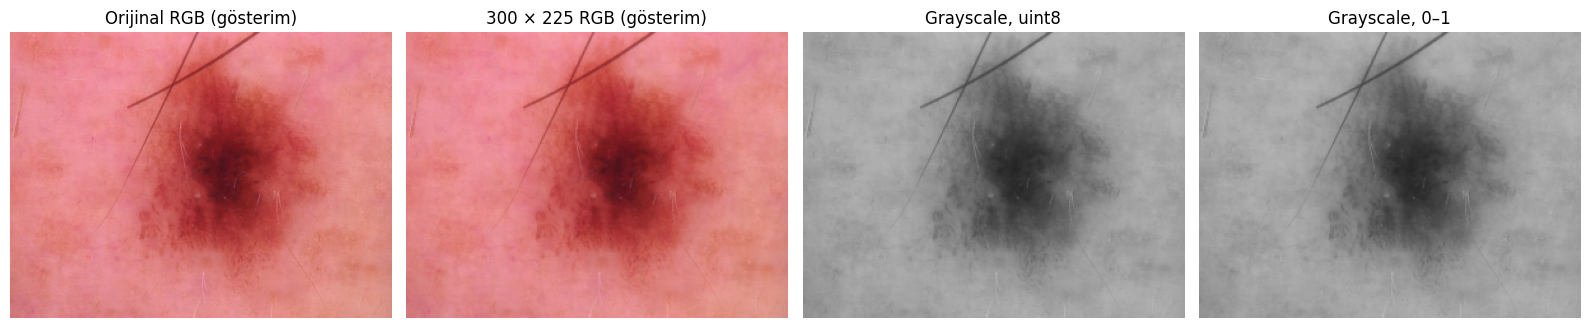

In [5]:
sample = df.iloc[0]
original_bgr = read_image(sample["image_path"])
resized_bgr = resize_image(original_bgr, SIZE)
gray = convert_grayscale(resized_bgr)
gray_normalized = normalize_image(gray)

print("Orijinal shape (H, W, C):", original_bgr.shape)
print("Resize shape:", resized_bgr.shape)
print("Grayscale shape:", gray.shape)
print("Normalize dtype ve aralık:", gray_normalized.dtype, float(gray_normalized.min()), float(gray_normalized.max()))
assert resized_bgr.shape == (*EXPECTED_HW, 3)
assert gray.shape == EXPECTED_HW
assert gray_normalized.dtype == np.float32
assert 0 <= gray_normalized.min() <= gray_normalized.max() <= 1

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)); axes[0].set_title("Orijinal RGB (gösterim)")
axes[1].imshow(cv2.cvtColor(resized_bgr, cv2.COLOR_BGR2RGB)); axes[1].set_title("300 × 225 RGB (gösterim)")
axes[2].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[2].set_title("Grayscale, uint8")
axes[3].imshow(gray_normalized, cmap="gray", vmin=0, vmax=1); axes[3].set_title("Grayscale, 0–1")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Segmentasyon maskesi: bir kez uygula, BGR ve grayscale çıktıları kontrol et

Görüntüye maske uygulanırken gerçek maske önce **nearest-neighbor** ile yeniden boyutlandırılır, ardından 0/255 biçiminde ikili hale getirilir. Bu mantık `src.preprocessing.preprocess_with_mask()` fonksiyonunda zaten bulunur; burada yeniden tanımlanmaz.

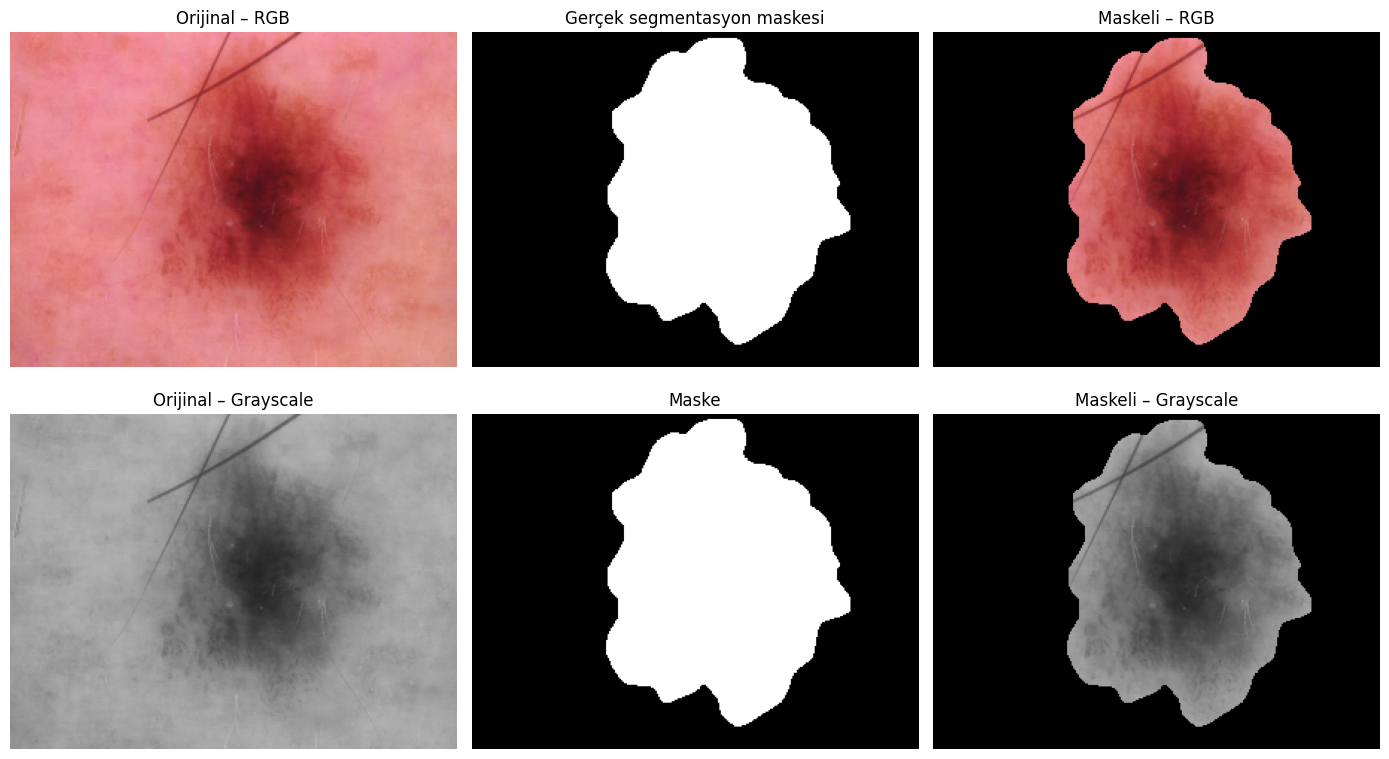

Maske doluluk oranı (%): 34.29
Maskede kullanılan değerler: [  0 255]


In [6]:
original_color_bgr = preprocess_image(sample["image_path"], size=SIZE, grayscale=False, normalize=False)
masked_color_bgr, binary_mask = preprocess_with_mask(
    sample["image_path"], sample["mask_path"], size=SIZE,
    grayscale=False, normalize=False,
)
original_gray = preprocess_image(sample["image_path"], size=SIZE, grayscale=True, normalize=False)
masked_gray, binary_mask_gray = preprocess_with_mask(
    sample["image_path"], sample["mask_path"], size=SIZE,
    grayscale=True, normalize=False,
)
assert original_color_bgr.shape == (*EXPECTED_HW, 3)
assert masked_color_bgr.shape == (*EXPECTED_HW, 3)
assert original_gray.shape == EXPECTED_HW
assert masked_gray.shape == EXPECTED_HW
assert binary_mask.shape == EXPECTED_HW
assert np.isin(binary_mask, [0, 255]).all()
assert np.array_equal(binary_mask, binary_mask_gray)
assert np.all(masked_color_bgr[binary_mask == 0] == 0)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes[0, 0].imshow(cv2.cvtColor(original_color_bgr, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Orijinal – RGB")
axes[0, 1].imshow(binary_mask, cmap="gray", vmin=0, vmax=255); axes[0, 1].set_title("Gerçek segmentasyon maskesi")
axes[0, 2].imshow(cv2.cvtColor(masked_color_bgr, cv2.COLOR_BGR2RGB)); axes[0, 2].set_title("Maskeli – RGB")
axes[1, 0].imshow(original_gray, cmap="gray", vmin=0, vmax=255); axes[1, 0].set_title("Orijinal – Grayscale")
axes[1, 1].imshow(binary_mask, cmap="gray", vmin=0, vmax=255); axes[1, 1].set_title("Maske")
axes[1, 2].imshow(masked_gray, cmap="gray", vmin=0, vmax=255); axes[1, 2].set_title("Maskeli – Grayscale")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

print("Maske doluluk oranı (%):", round(100 * np.count_nonzero(binary_mask) / binary_mask.size, 2))
print("Maskede kullanılan değerler:", np.unique(binary_mask))

## 4. Model türlerine göre hangi görüntü hazırlanmalı?

| Model ailesi | Bu notebook’taki giriş | Açıklama |
|---|---|---|
| HOG + RF/LR/OvR/XGBoost | `original_gray` veya `masked_gray` | HOG öznitelikleri daha sonra `src/features.py` ile çıkarılır. |
| Color + RF/LR | `original_color_bgr` veya `masked_color_bgr` | HSV/RGB özellik çıkarırken renk uzayı açıkça belirlenmelidir. |
| CNN/EfficientNet | `cv2.cvtColor(original_color_bgr, cv2.COLOR_BGR2RGB)` | CNN girişinde RGB ve uygun giriş boyutu; modele özgü ölçekleme. |

**Not:** Buradaki `300 × 225` boyutu yalnızca mevcut klasik ML deneylerinin ayarıdır. EfficientNet için aynı boyutu zorunlu tutmayın. Bu notebook ayrıca train/validation/test bölmez; bölme tüm modellerde ortak, sabit bir aşamada yapılmalıdır.

## 5. Ön işleme doğrulaması (isteğe bağlı tüm veri seti kontrolü)

Tüm 10.015 görüntüye işlem uygulamak süre alır. Varsayılan olarak yalnızca **ilk 10 görüntü** kontrol edilir; ihtiyaç halinde `CHECK_ALL=True` yapabilirsiniz. Bu işlem özellik dosyalarını yeniden üretmez.

In [7]:
CHECK_ALL = False
N_SAMPLE = 10
rows_to_check = df if CHECK_ALL else df.head(N_SAMPLE)
errors = []
for _, row in rows_to_check.iterrows():
    try:
        color, mask = preprocess_with_mask(
            row["image_path"], row["mask_path"],
            size=SIZE, grayscale=False, normalize=False,
        )
        gray_masked, mask_gray = preprocess_with_mask(
            row["image_path"], row["mask_path"],
            size=SIZE, grayscale=True, normalize=False,
        )
        assert color.shape == (*EXPECTED_HW, 3), f"Renkli shape: {color.shape}"
        assert gray_masked.shape == EXPECTED_HW, f"Gray shape: {gray_masked.shape}"
        assert mask.shape == EXPECTED_HW, f"Maske shape: {mask.shape}"
        assert np.isin(mask, [0, 255]).all(), "İkili olmayan maske"
        assert np.array_equal(mask, mask_gray), "Renkli/grayscale maske farkı"
        assert np.count_nonzero(mask) > 0, "Boş maske"
    except Exception as exc:
        errors.append((row["image"], str(exc)))
print("Kontrol edilen görüntü:", len(rows_to_check))
print("Hatalı görüntü:", len(errors))
if errors:
    display(pd.DataFrame(errors, columns=["image", "error"]).head(20))
else:
    print("Kontroller başarılı.")

Kontrol edilen görüntü: 10
Hatalı görüntü: 0
Kontroller başarılı.


## 6. Sonuç ve sorumluluk sınırı

Bu notebook, görüntü okuma, boyutlandırma, renk gösterimi, grayscale, normalizasyon ve gerçek segmentasyon maskesi işlemlerini kontrol eder. **Özellik çıkarımı veya eğitim yapılmaz.** Model kıyaslarında aynı görüntü sırası ve aynı train/validation/test indeksleri kullanılmalı; mümkünse aynı hasta/lezyona ait görüntüler farklı kümelere dağıtılmamalıdır. Maske kullanan modelin yeni veride çalışabilmesi için de maske üretimi ayrı bir adım olarak gerekir.

In [ ]:
import winsound

winsound.Beep(300, 3000)
print("Ses testi tamamlandı.")